<a href="https://colab.research.google.com/github/raghavxi1/gym-attendance-analysis/blob/main/notebooks/02_eda_visuals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os
os.makedirs('images', exist_ok=True)
url = "https://raw.githubusercontent.com/raghavxi1/gym-attendance-analysis/main/data/clean/gym_clean.csv"
df = pd.read_csv(url)

def rate_ci(col, order=None):
    g = df.groupby(col)['is_present'].agg(['mean','count'])
    g['rate'] = g['mean'] * 100
    g['err'] = 1.96 * np.sqrt(g['mean'] * (1 - g['mean']) / g['count']) * 100
    return g.reindex(order) if order else g

overall = df['is_present'].mean() * 100

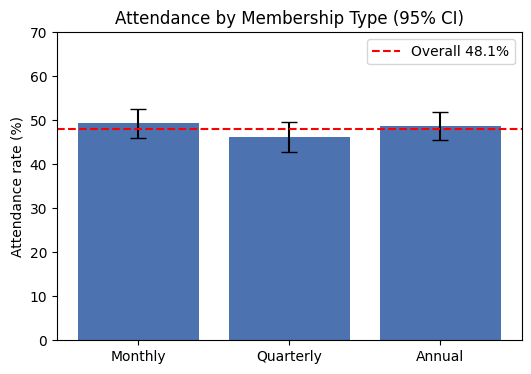

In [2]:
g = rate_ci('membership_type', ['Monthly','Quarterly','Annual'])
plt.figure(figsize=(6,4))
plt.bar(g.index, g['rate'], yerr=g['err'], capsize=6, color='#4C72B0')
plt.axhline(overall, color='red', ls='--', label=f'Overall {overall:.1f}%')
plt.ylabel('Attendance rate (%)'); plt.title('Attendance by Membership Type (95% CI)')
plt.legend(); plt.ylim(0,70); plt.savefig('images/attendance_by_membership.png', dpi=150, bbox_inches='tight'); plt.show()

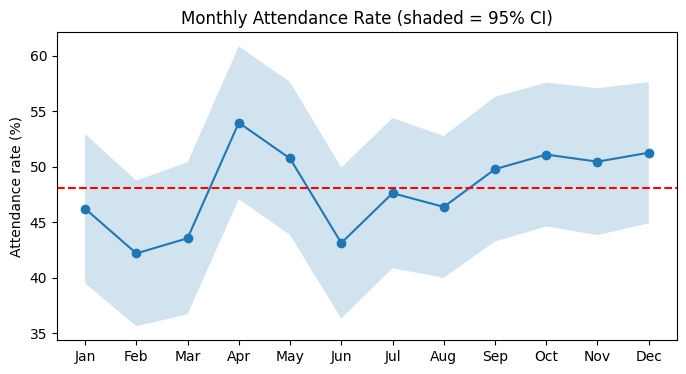

In [3]:
g = rate_ci('month')
plt.figure(figsize=(8,4))
plt.plot(g.index, g['rate'], marker='o')
plt.fill_between(g.index, g['rate']-g['err'], g['rate']+g['err'], alpha=0.2)
plt.axhline(overall, color='red', ls='--')
plt.xticks(range(1,13), ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
plt.ylabel('Attendance rate (%)'); plt.title('Monthly Attendance Rate (shaded = 95% CI)')
plt.savefig('images/monthly_attendance.png', dpi=150, bbox_inches='tight'); plt.show()

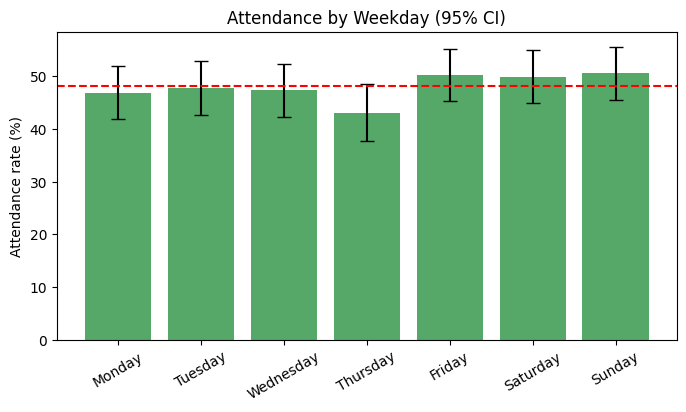

In [4]:
days = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
g = rate_ci('weekday', days)
plt.figure(figsize=(8,4))
plt.bar(days, g['rate'], yerr=g['err'], capsize=5, color='#55A868')
plt.axhline(overall, color='red', ls='--')
plt.xticks(rotation=30); plt.ylabel('Attendance rate (%)'); plt.title('Attendance by Weekday (95% CI)')
plt.savefig('images/weekday_attendance.png', dpi=150, bbox_inches='tight'); plt.show()

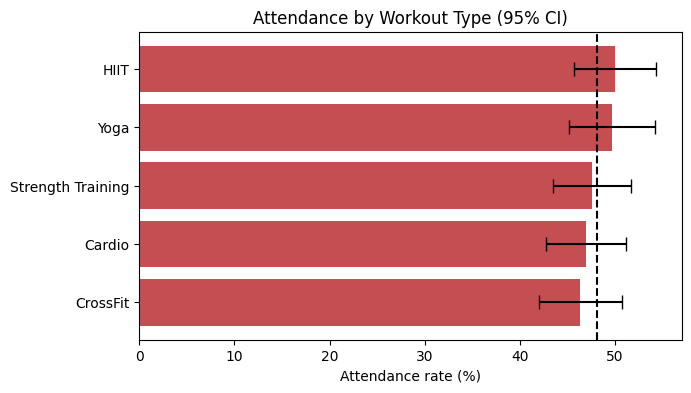

In [5]:
g = rate_ci('workout_type').sort_values('rate')
plt.figure(figsize=(7,4))
plt.barh(g.index, g['rate'], xerr=g['err'], capsize=5, color='#C44E52')
plt.axvline(overall, color='black', ls='--')
plt.xlabel('Attendance rate (%)'); plt.title('Attendance by Workout Type (95% CI)')
plt.savefig('images/workout_type_attendance.png', dpi=150, bbox_inches='tight'); plt.show()

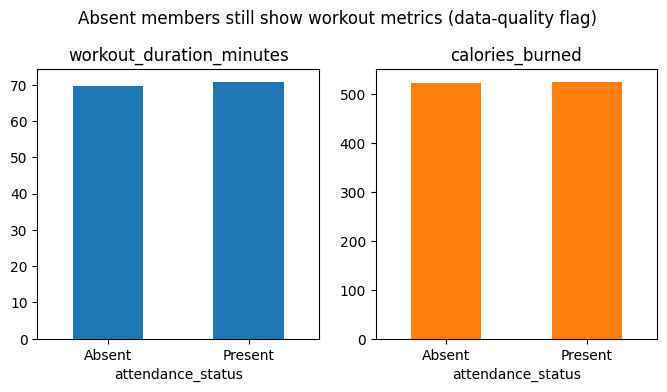

In [6]:
g = df.groupby('attendance_status')[['workout_duration_minutes','calories_burned']].mean()
g.plot(kind='bar', subplots=True, layout=(1,2), figsize=(8,3.5), legend=False, rot=0)
plt.suptitle('Absent members still show workout metrics (data-quality flag)', y=1.05)
plt.savefig('images/data_quality_absent.png', dpi=150, bbox_inches='tight'); plt.show()

In [7]:
from scipy.stats import chi2_contingency
res = {c: chi2_contingency(pd.crosstab(df[c], df['is_present']))[1]
       for c in ['membership_type','weekday','month','workout_type','age_group','gender','is_weekend','check_in_hour']}
display(pd.Series(res, name='p_value').round(3))

!zip -qr images.zip images
from google.colab import files
files.download('images.zip')

,p_value
membership_type,0.380
weekday,0.456
month,0.282
workout_type,0.705
age_group,0.448
gender,0.603
is_weekend,0.179
check_in_hour,0.789


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>